# Practical 7 - CNNs, CVAT, YOLO and Cellpose

**Machine Learning for Bioinformatics**

This practical moves from image inspection to image classification, object detection, instance segmentation and a compact 3D embedding workflow. The examples use blood-cell images, bacterial colonies and microscopy images.

## Learning objectives

By the end of the practical, you should be able to:

- inspect image shape, dtype, channels and intensity range;
- perform a small EDA of class balance and image-level t-SNE structure;
- train a small CNN for blood-cell classification;
- compare depth, channel width, batch normalization, dropout and global average pooling;
- compare classification accuracy with and without biologically valid augmentation;
- adapt a pretrained VGG16 by freezing its convolutional backbone;
- explain why image classification, detection and segmentation require different labels;
- inspect and validate CVAT/YOLO annotations;
- compare YOLOv8, YOLO11 and YOLO26 under a common experimental protocol;
- use Cellpose as a pretrained instance-segmentation model;
- inspect a 3D microscopy volume with Napari and construct a VGG13D-style embedding.

In [1]:

from pathlib import Path
import random
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

RANDOM_STATE = 221026
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


RUN_DATA_DOWNLOAD = True
RUN_EXPENSIVE = True
SHOW_PLOTS = True



print('PyTorch:', torch.__version__)
print('Device:', DEVICE)


PyTorch: 2.11.0+cu128
Device: cuda


# Part I - Image and annotation inspection

Before modeling, inspect the data as an imaging experiment rather than assuming that every file is a clean RGB image. Check file type, image mode, spatial dimensions, number of channels, data type, intensity range, unreadable files and annotation availability. The same checks should be repeated after any conversion or export step. These properties determine which transforms and model inputs are safe: for example, a grayscale image should not silently be treated as a meaningful three-channel RGB image, and a 16-bit intensity range should not be normalized as if it were 8-bit.

In [2]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

def locate_week7_root():
    current = Path.cwd().resolve()
    candidates = [current, *current.parents]
    for base in candidates:
        for candidate in (base, base / 'week7'):
            if (candidate / 'detection').is_dir() and any((candidate / name).is_dir() for name in ('segemntation', 'segmentation')):
                return candidate
    return current / 'week7'

# Resolve the root before constructing task-specific paths. 
WEEK7_ROOT = locate_week7_root()
PROJECT_ROOT = WEEK7_ROOT.parent
DATA_ROOT = WEEK7_ROOT
CLASSIFICATION_ROOT = DATA_ROOT / 'classification'
DETECTION_ROOT = DATA_ROOT / 'detection' / 'colonies_annotation'
SEGMENTATION_ROOT = next((DATA_ROOT / name for name in ('segemntation', 'segmentation') if (DATA_ROOT / name).is_dir()), DATA_ROOT / 'segmentation')
def image_inventory_row(path, source):
    row = {'source': source, 'file': str(path), 'readable': False}
    try:
        with Image.open(path) as image:
            array = np.asarray(image)
            row.update({
                'readable': True,
                'format': image.format,
                'mode': image.mode,
                'width': image.width,
                'height': image.height,
                'array_shape': tuple(array.shape),
                'dtype': str(array.dtype),
                'channels': 1 if array.ndim == 2 else array.shape[-1],
                'min_intensity': float(np.nanmin(array)),
                'max_intensity': float(np.nanmax(array)),
                'finite': bool(np.isfinite(array).all()),
            })
    except Exception as error:
        row['error'] = repr(error)
    return row

inspection_groups = {
    'detection': sorted((DETECTION_ROOT / 'obj_train_data').glob('*')) if (DETECTION_ROOT / 'obj_train_data').exists() else [],
    'brightfield': sorted((SEGMENTATION_ROOT / 'brightfield').glob('*')) if (SEGMENTATION_ROOT / 'brightfield').exists() else [],
    'CLSM': sorted((SEGMENTATION_ROOT / 'clsm').glob('*')) if (SEGMENTATION_ROOT / 'clsm').exists() else [],
}
inventory_rows = []
for source, paths in inspection_groups.items():
    image_paths = [path for path in paths if path.suffix.lower() in IMAGE_EXTENSIONS]
    for path in image_paths[:5]:
        inventory_rows.append(image_inventory_row(path, source))

if inventory_rows:
    image_inventory = pd.DataFrame(inventory_rows)
    display(image_inventory)
    print('Unreadable files:', int((~image_inventory['readable']).sum()))
else:
    image_inventory = pd.DataFrame()
    print('No local detection or segmentation images were found; continue with the checks after mounting the data.')

,source,file,readable,format,mode,width,height,array_shape,dtype,channels,min_intensity,max_intensity,finite
0,detection,C:\Users\user\Desktop\kse\practicals\week7\det...,True,JPEG,RGB,850,567,"(567, 850, 3)",uint8,3,0.0,255.0,True
1,detection,C:\Users\user\Desktop\kse\practicals\week7\det...,True,JPEG,RGB,850,567,"(567, 850, 3)",uint8,3,0.0,255.0,True
2,detection,C:\Users\user\Desktop\kse\practicals\week7\det...,True,JPEG,RGB,850,567,"(567, 850, 3)",uint8,3,0.0,255.0,True
3,detection,C:\Users\user\Desktop\kse\practicals\week7\det...,True,JPEG,RGB,850,567,"(567, 850, 3)",uint8,3,0.0,255.0,True
4,detection,C:\Users\user\Desktop\kse\practicals\week7\det...,True,JPEG,RGB,850,567,"(567, 850, 3)",uint8,3,0.0,255.0,True
5,brightfield,C:\Users\user\Desktop\kse\practicals\week7\seg...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,32.0,255.0,True
6,brightfield,C:\Users\user\Desktop\kse\practicals\week7\seg...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,54.0,255.0,True
7,brightfield,C:\Users\user\Desktop\kse\practicals\week7\seg...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,47.0,255.0,True
8,brightfield,C:\Users\user\Desktop\kse\practicals\week7\seg...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,0.0,255.0,True
9,brightfield,C:\Users\user\Desktop\kse\practicals\week7\seg...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,0.0,255.0,True


Unreadable files: 0


# Part II - Blood-cell image classification

For classification we use the Kaggle Blood Cells Image Dataset. The dataset contains labelled cell images arranged into class folders. The notebook discovers the folder structure after download rather than assuming a fixed number of classes.

Dataset source: [unclesamulus/blood-cells-image-dataset](https://www.kaggle.com/datasets/unclesamulus/blood-cells-image-dataset).

The `ImageFolder` convention is important here: each immediate subfolder is interpreted as one class, and the folder name becomes the class label. This is convenient, but it also means that a wrong folder level or an accidental directory can change the labels. We therefore discover and inspect the folder before creating the PyTorch dataset.

In [3]:
classification_download = None
if RUN_DATA_DOWNLOAD:
    import kagglehub
    classification_download = Path(kagglehub.dataset_download('unclesamulus/blood-cells-image-dataset'))
    print('Path to dataset files:', classification_download)
else:
    print('Kaggle download skipped. Set RUN_DATA_DOWNLOAD=True when network access is available.')


Path to dataset files: C:\Users\user\.cache\kagglehub\datasets\unclesamulus\blood-cells-image-dataset\versions\2


In [4]:
def has_imagefolder_classes(directory):
    if not directory.is_dir():
        return False
    class_dirs = [child for child in directory.iterdir() if child.is_dir()]
    return len(class_dirs) >= 2 and all(
        any(file.suffix.lower() in {'.jpg', '.jpeg', '.png', '.tif', '.tiff'} for file in child.iterdir())
        for child in class_dirs
    )

def find_imagefolder_root(root):
    candidates = [root] + sorted(path for path in root.rglob('*') if path.is_dir())
    valid = [path for path in candidates if has_imagefolder_classes(path)]
    if not valid:
        return None
    return max(valid, key=lambda path: len(list(path.iterdir())))

classification_candidates = [path for path in (classification_download, CLASSIFICATION_ROOT) if path is not None and path.exists()]
classification_root = next((find_imagefolder_root(path) for path in classification_candidates if find_imagefolder_root(path) is not None), None)
if classification_root:
    class_counts = {
        directory.name: sum(1 for file in directory.iterdir() if file.suffix.lower() in {'.jpg', '.jpeg', '.png', '.tif', '.tiff'})
        for directory in sorted(classification_root.iterdir()) if directory.is_dir()
    }
    display(pd.Series(class_counts, name='images').sort_values(ascending=False))
else:
    print('Classification folder not available.')

neutrophil      3329
eosinophil      3117
ig              2895
platelet        2348
erythroblast    1551
monocyte        1420
basophil        1218
lymphocyte      1214
Name: images, dtype: int64

## Classification EDA: class balance and t-SNE

Before fitting a CNN, inspect whether classes are balanced and whether a simple low-dimensional view shows obvious structure. For speed, t-SNE uses a stratified subset and small grayscale thumbnails. This is an exploratory visualization, not a replacement for a held-out evaluation.

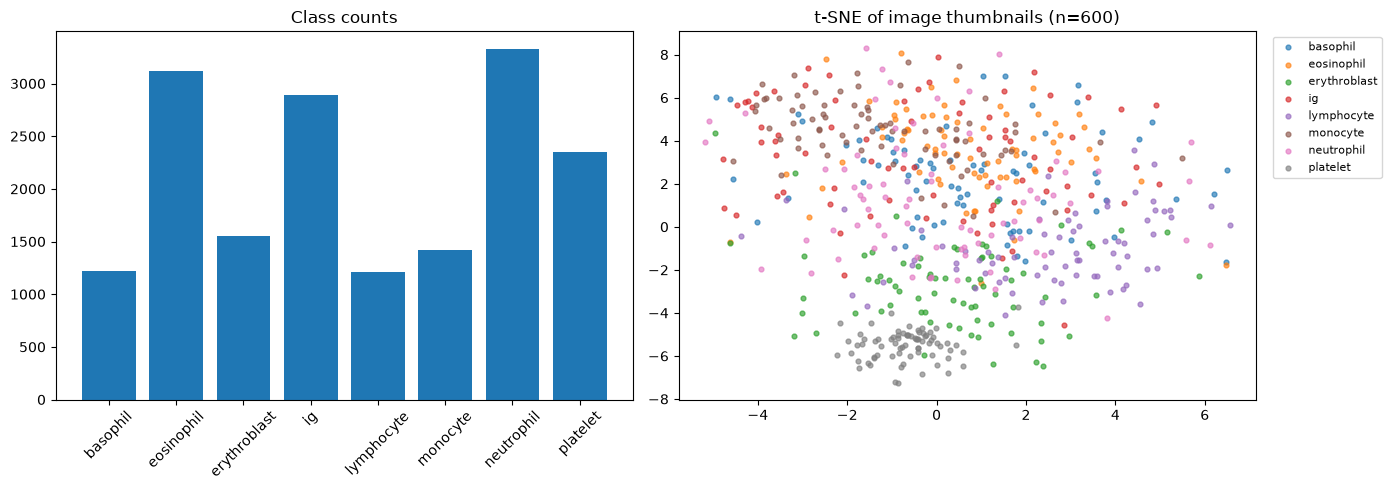

In [5]:
# This exploratory view uses low-resolution grayscale thumbnails only to
# make the computation manageable. It is not the representation used by
# the CNN and should not be interpreted as a performance estimate.
if classification_root is not None:
    from sklearn.manifold import TSNE
    from sklearn.preprocessing import StandardScaler
    image_dataset = datasets.ImageFolder(classification_root)
    CLASS_NAMES = image_dataset.classes
    targets = np.asarray(image_dataset.targets)

    eda_rng = np.random.default_rng(RANDOM_STATE)
    max_eda_images = 600
    eda_indices = []
    per_class = max(1, max_eda_images // len(CLASS_NAMES))
    for class_id in range(len(CLASS_NAMES)):
        class_indices = np.flatnonzero(targets == class_id)
        take = min(per_class, len(class_indices))
        eda_indices.extend(eda_rng.choice(class_indices, size=take, replace=False).tolist())

    eda_features, eda_labels = [], []
    for index in eda_indices:
        image_path, label = image_dataset.samples[index]
        with Image.open(image_path) as image:
            thumbnail = np.asarray(image.convert('L').resize((32, 32)), dtype=np.float32) / 255.0
        eda_features.append(thumbnail.ravel())
        eda_labels.append(label)

    eda_features = StandardScaler().fit_transform(np.asarray(eda_features))
    eda_labels = np.asarray(eda_labels)
    if len(eda_features) >= 4:
        eda_perplexity = min(30, max(2, (len(eda_features) - 1) // 3))
        eda_embedding = TSNE(n_components=2, perplexity=eda_perplexity, init='pca', learning_rate='auto', random_state=RANDOM_STATE).fit_transform(eda_features)
        figure, axes = plt.subplots(1, 2, figsize=(14, 5))
        axes[0].bar(CLASS_NAMES, [int(np.sum(targets == class_id)) for class_id in range(len(CLASS_NAMES))])
        axes[0].set_title('Class counts')
        axes[0].tick_params(axis='x', rotation=45)
        for class_id, class_name in enumerate(CLASS_NAMES):
            mask = eda_labels == class_id
            axes[1].scatter(eda_embedding[mask, 0], eda_embedding[mask, 1], s=12, alpha=0.65, label=class_name)
        axes[1].set_title(f't-SNE of image thumbnails (n={len(eda_features)})')
        axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
        plt.tight_layout()
        plt.show()
    else:
        print('Too few images for t-SNE.')
else:
    print('Classification EDA skipped because the dataset is unavailable.')

## What does a convolution kernel do to a blood-cell image?

A convolution kernel is a small learned or hand-designed matrix that slides across an image. At each location it computes a weighted local sum. Different kernels emphasize different local structures: a blur averages neighboring pixels, Sobel-like kernels emphasize edges, and a sharpening kernel emphasizes local contrast. The first demonstration uses hand-designed kernels; after the baseline CNN is trained, we also inspect the feature maps produced by its learned convolutional layers.

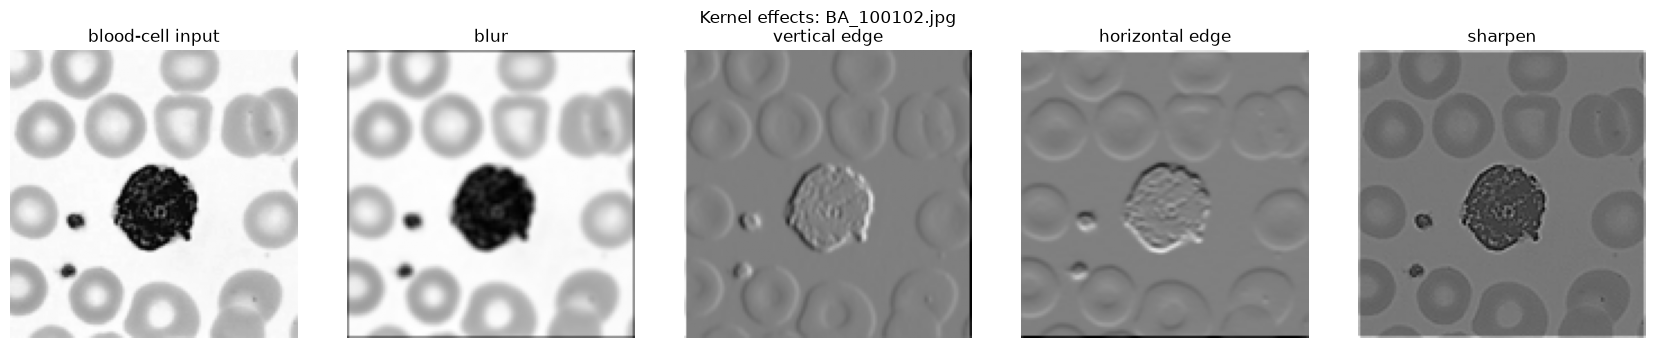

In [6]:
if classification_root is not None and len(image_dataset) > 0:
    kernel_source = Path(image_dataset.samples[0][0])
    demo_image = np.asarray(
        Image.open(kernel_source).convert('L').resize((128, 128)),
        dtype=np.float32,
    ) / 255.0
else:
    kernel_source = None
    yy, xx = np.mgrid[-1:1:128j, -1:1:128j]
    demo_image = np.exp(-((xx - 0.3) ** 2 + (yy + 0.1) ** 2) / 0.08)

kernels = {
    'blur': np.ones((3, 3), dtype=np.float32) / 9,
    'vertical edge': np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32),
    'horizontal edge': np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32),
    'sharpen': np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32),
}
input_tensor = torch.from_numpy(demo_image.astype(np.float32))[None, None]
filtered = {
    name: F.conv2d(input_tensor, torch.from_numpy(kernel)[None, None], padding=1)[0, 0].numpy()
    for name, kernel in kernels.items()
}

if SHOW_PLOTS:
    figure, axes = plt.subplots(1, 5, figsize=(17, 3.5))
    axes[0].imshow(demo_image, cmap='gray')
    axes[0].set_title('blood-cell input')
    for axis, (name, output) in zip(axes[1:], filtered.items()):
        axis.imshow(output, cmap='gray')
        axis.set_title(name)
    for axis in axes:
        axis.axis('off')
    figure.suptitle(f'Kernel effects: {kernel_source.name if kernel_source else "fallback image"}')
    plt.tight_layout()
    plt.show()

## Classification split and deterministic baseline transforms

If the downloaded dataset contains predefined `TRAIN` and `TEST` folders, preserve that separation and create validation data from the training part. Otherwise, create a stratified train/validation/test split.

For the baseline CNN and the architecture comparison, we use only deterministic preprocessing: resize and conversion to a tensor. Random augmentation is introduced later as its own experiment, so any accuracy difference can be attributed to augmentation rather than being mixed into the baseline.

In [7]:
# The baseline receives a stable representation of every image.
IMAGE_SIZE = 128
BATCH_SIZE = 32
base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
train_transform = base_transform
eval_transform = base_transform

train_loader = val_loader = test_loader = None
CLASS_NAMES = []
classification_ready = classification_root is not None

if classification_ready:
    image_dataset = datasets.ImageFolder(classification_root)
    CLASS_NAMES = image_dataset.classes
    targets = np.asarray(image_dataset.targets)
    indices = np.arange(len(image_dataset))
    train_indices, temporary_indices = train_test_split(
        indices, test_size=0.2, random_state=RANDOM_STATE, stratify=targets,
    )
    temporary_targets = targets[temporary_indices]
    val_indices, test_indices = train_test_split(
        temporary_indices, test_size=0.5,
        random_state=RANDOM_STATE, stratify=temporary_targets,
    )
    train_source = datasets.ImageFolder(classification_root, transform=train_transform)
    eval_source = datasets.ImageFolder(classification_root, transform=eval_transform)
    train_dataset = Subset(train_source, train_indices)
    val_dataset = Subset(eval_source, val_indices)
    test_dataset = Subset(eval_source, test_indices)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    print('Classes:', CLASS_NAMES)
    print('Split sizes:', len(train_dataset), len(val_dataset), len(test_dataset))
else:
    print('Classification data are not available. Set RUN_DATA_DOWNLOAD=True and rerun this section.')

Classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Split sizes: 13673 1709 1710


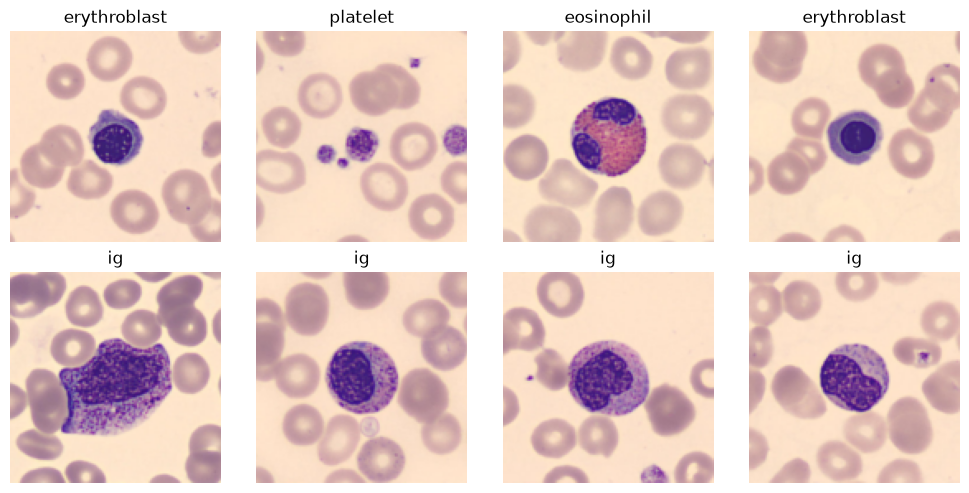

In [8]:
if classification_ready and SHOW_PLOTS:
    batch_images, batch_labels = next(iter(train_loader))
    figure, axes = plt.subplots(2, 4, figsize=(10, 5))
    for axis, image, label in zip(axes.ravel(), batch_images[:8], batch_labels[:8]):
        axis.imshow(image.permute(1, 2, 0).numpy())
        axis.set_title(CLASS_NAMES[int(label)])
        axis.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Baseline batch preview skipped because classification data are unavailable or SHOW_PLOTS=False.')

## Baseline CNN

The classifier produces one logit per class. A logit is an unnormalized score: larger values indicate that the model prefers that class, but the values do not yet need to sum to one. `CrossEntropyLoss` expects logits, so a softmax layer is not added before the loss; the loss applies the numerically stable log-softmax operation internally. During prediction, `argmax` selects the class with the largest logit.

The baseline has two convolution--ReLU--pooling blocks. Convolutions learn local visual patterns, pooling reduces spatial resolution, and the final linear layer maps the learned representation to the class scores.

In [9]:
class SimpleCNN(nn.Module):
    def __init__(self, in_channels, n_classes, image_size=128):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        reduced = image_size // 4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * reduced * reduced, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


model = None
if classification_ready:
    model = SimpleCNN(3, len(CLASS_NAMES), IMAGE_SIZE).to(DEVICE)
    print(model)
    print('Trainable parameters:', count_parameters(model))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=8, bias=True)
  )
)
Trainable parameters: 267240


## Comparing CNN architectures

A larger or deeper network is not automatically better. Compare the number of trainable parameters and the feature-map strategy. The baseline flattens a spatial feature map, while the global-average-pooling model keeps fewer parameters and summarizes each learned feature map. The deeper model adds another convolutional representation. The configurable experiment later changes one factor at a time: depth, channel width, batch normalization, dropout or global average pooling. This is not a full hyperparameter search; it is a controlled teaching experiment. The optional training loop below is guarded by `RUN_EXPENSIVE`.

In [10]:
class GAPCNN(nn.Module):
    def __init__(self, in_channels, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(32, n_classes)

    def forward(self, x):
        features = self.features(x)
        return self.classifier(features.mean(dim=(2, 3)))

class DeeperCNN(nn.Module):
    def __init__(self, in_channels, n_classes, image_size=128):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        reduced = image_size // 8
        self.classifier = nn.Linear(64 * reduced * reduced, n_classes)

    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))


In [11]:
if classification_ready:
    n_demo_classes = len(CLASS_NAMES)
    architecture_models = {
        'baseline / flatten': SimpleCNN(3, n_demo_classes, IMAGE_SIZE),
        'global average pooling': GAPCNN(3, n_demo_classes),
        'deeper / flatten': DeeperCNN(3, n_demo_classes, IMAGE_SIZE),
    }
    architecture_table = pd.DataFrame([
        {'architecture': name, 'trainable_parameters': count_parameters(candidate)}
        for name, candidate in architecture_models.items()
    ])
    display(architecture_table)
    with torch.no_grad():
        demo_batch = torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE)
        print({name: tuple(candidate(demo_batch).shape) for name, candidate in architecture_models.items()})
else:
    architecture_models = {}
    print('Architecture inspection skipped because classification data are unavailable.')

,architecture,trainable_parameters
0,baseline / flatten,267240
1,global average pooling,5352
2,deeper / flatten,154664


{'baseline / flatten': (2, 8), 'global average pooling': (2, 8), 'deeper / flatten': (2, 8)}


In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    # One epoch means one pass through the training subset.
    model.train()
    total_loss, y_true, y_pred = 0.0, [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(logits.argmax(1).detach().cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(y_true, y_pred)


@torch.no_grad()
def evaluate_classifier(model, loader, criterion, device):
    model.eval()
    total_loss, y_true, y_pred = 0.0, [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * images.size(0)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(logits.argmax(1).cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(y_true, y_pred), np.asarray(y_true), np.asarray(y_pred)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
if classification_ready and RUN_EXPENSIVE:
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(10):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_acc, _, _ = evaluate_classifier(model, val_loader, criterion, DEVICE)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        print(f'{epoch + 1:02d} | train={train_acc:.3f} | val={val_acc:.3f}')
else:
    print('Baseline CNN training skipped. Set RUN_EXPENSIVE=True to train.')

01 | train=0.557 | val=0.733
02 | train=0.783 | val=0.823
03 | train=0.860 | val=0.869
04 | train=0.901 | val=0.889
05 | train=0.923 | val=0.899
06 | train=0.940 | val=0.897
07 | train=0.947 | val=0.908
08 | train=0.962 | val=0.919
09 | train=0.962 | val=0.920
10 | train=0.968 | val=0.925


## Feature maps from the learned CNN convolutions

The filters in a CNN are learned from the training data. A forward hook lets us capture the output of each `Conv2d` layer without changing the model. We display one representative feature map per convolutional layer: the channel with the largest spatial variance. Early maps often respond to simple edges or textures, while later maps combine these local patterns into more task-specific structures. If training was skipped, the model is untrained and the maps are only a tensor-shape demonstration.

In [ ]:
learned_conv_activations = {}

if classification_ready and model is not None and len(image_dataset) > 0:
    activation_source = Path(image_dataset.samples[0][0])
    with Image.open(activation_source) as source_image:
        activation_image = source_image.convert('RGB')
        activation_tensor = eval_transform(activation_image).unsqueeze(0).to(DEVICE)

    hooks = []
    for layer_name, layer in model.named_modules():
        if isinstance(layer, nn.Conv2d):
            hooks.append(layer.register_forward_hook(
                lambda module, inputs, output, name=layer_name: learned_conv_activations.__setitem__(
                    name, output.detach().cpu()
                )
            ))

    model.eval()
    with torch.no_grad():
        activation_logits = model(activation_tensor)
    for hook in hooks:
        hook.remove()

    prediction_index = int(activation_logits.argmax(dim=1).item())
    print('Image:', activation_source.name)
    if CLASS_NAMES:
        print('Predicted class:', CLASS_NAMES[prediction_index])

    if SHOW_PLOTS:
        figure, axes = plt.subplots(1, 1 + len(learned_conv_activations), figsize=(5 * (1 + len(learned_conv_activations)), 5), squeeze=False)
        axes = axes.ravel()
        axes[0].imshow(np.asarray(activation_image.resize((IMAGE_SIZE, IMAGE_SIZE))))
        axes[0].set_title('Input image')
        axes[0].axis('off')
        for axis, (layer_name, activation) in zip(axes[1:], learned_conv_activations.items()):
            feature_maps = activation[0]
            channel_index = int(feature_maps.flatten(start_dim=1).var(dim=1).argmax())
            feature_map = feature_maps[channel_index].numpy()
            axis.imshow(feature_map, cmap='magma')
            axis.set_title(f'{layer_name}\nchannel {channel_index}')
            axis.axis('off')
        figure.suptitle('Representative feature maps from each CNN convolutional layer', y=1.02)
        plt.tight_layout()
        plt.show()
else:
    print('CNN activation inspection skipped because the classification model or data are unavailable.')

## Baseline CNN experiments

We now change one architectural factor at a time while keeping the split, optimizer and training budget fixed. The experiments are: deeper network, wider channels, batch normalization, dropout and global average pooling. Parameter counts are informative, but the final comparison must use the same validation protocol. In a real study, each result should be repeated with several random seeds and reported with uncertainty; a single short run is an illustration, not definitive evidence that one architecture is biologically superior.

In [13]:
class ConfigurableCNN(nn.Module):
    def __init__(self, in_channels, n_classes, image_size=128, depth=2, base_channels=16, batch_norm=False, dropout=0.0, global_average_pooling=False):
        super().__init__()
        blocks, channels = [], []
        current_channels = in_channels
        for level in range(depth):
            output_channels = base_channels * (2 ** level)
            blocks.append(nn.Conv2d(current_channels, output_channels, kernel_size=3, padding=1))
            if batch_norm:
                blocks.append(nn.BatchNorm2d(output_channels))
            blocks.extend([nn.ReLU(), nn.MaxPool2d(2)])
            channels.append(output_channels)
            current_channels = output_channels
        self.features = nn.Sequential(*blocks)
        if global_average_pooling:
            classifier_input = channels[-1]
            self.pool = nn.AdaptiveAvgPool2d((1, 1))
        else:
            reduced = image_size // (2 ** depth)
            classifier_input = channels[-1] * reduced * reduced
            self.pool = nn.Identity()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(classifier_input, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))



In [14]:

VARIANT_CONFIGS = {
    'baseline': dict(depth=2, base_channels=16),
    'deeper': dict(depth=3, base_channels=16),
    'wider channels': dict(depth=2, base_channels=32),
    'batch normalization': dict(depth=2, base_channels=16, batch_norm=True),
    'dropout': dict(depth=2, base_channels=16, dropout=0.35),
    'global average pooling': dict(depth=2, base_channels=16, global_average_pooling=True),
}
n_variant_classes = len(CLASS_NAMES) if CLASS_NAMES else 2
variant_models = {
    name: ConfigurableCNN(3, n_variant_classes, IMAGE_SIZE, **config)
    for name, config in VARIANT_CONFIGS.items()
}
display(pd.DataFrame([
    {'variant': name, 'parameters': count_parameters(candidate)}
    for name, candidate in variant_models.items()
]))

variant_results = pd.DataFrame()
if classification_ready and RUN_EXPENSIVE:
    result_rows = []
    for name, candidate in variant_models.items():
        candidate = candidate.to(DEVICE)
        variant_criterion = nn.CrossEntropyLoss()
        variant_optimizer = torch.optim.Adam(candidate.parameters(), lr=1e-3)
        best_val_accuracy = 0.0
        for _ in range(3):
            train_one_epoch(candidate, train_loader, variant_criterion, variant_optimizer, DEVICE)
            _, val_accuracy, _, _ = evaluate_classifier(candidate, val_loader, variant_criterion, DEVICE)
            best_val_accuracy = max(best_val_accuracy, val_accuracy)
        result_rows.append({'variant': name, 'best_val_accuracy': best_val_accuracy})
    variant_results = pd.DataFrame(result_rows).sort_values('best_val_accuracy', ascending=False)
    display(variant_results)
else:
    print('Architecture training skipped. Set RUN_EXPENSIVE=True to compare variants.')

,variant,parameters
0,baseline,267240
1,deeper,154664
2,wider channels,543688
3,batch normalization,267336
4,dropout,267240
5,global average pooling,5352


,variant,best_val_accuracy
1,deeper,0.908719
0,baseline,0.893505
3,batch normalization,0.888239
4,dropout,0.825044
2,wider channels,0.794032
5,global average pooling,0.488590


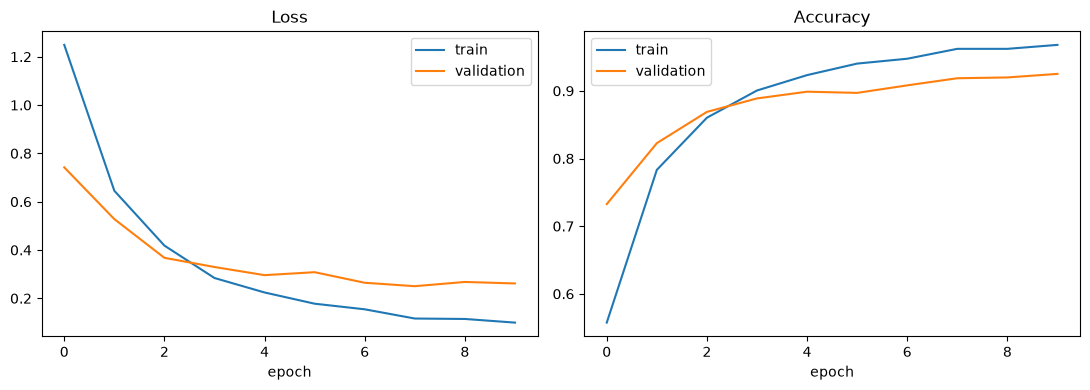

Test accuracy: 0.9192982456140351
              precision    recall  f1-score   support

    basophil       0.97      0.92      0.94       122
  eosinophil       0.99      0.98      0.99       312
erythroblast       0.89      0.95      0.92       155
          ig       0.84      0.78      0.81       290
  lymphocyte       0.88      0.93      0.91       121
    monocyte       0.75      0.81      0.78       142
  neutrophil       0.95      0.95      0.95       333
    platelet       1.00      1.00      1.00       235

    accuracy                           0.92      1710
   macro avg       0.91      0.92      0.91      1710
weighted avg       0.92      0.92      0.92      1710



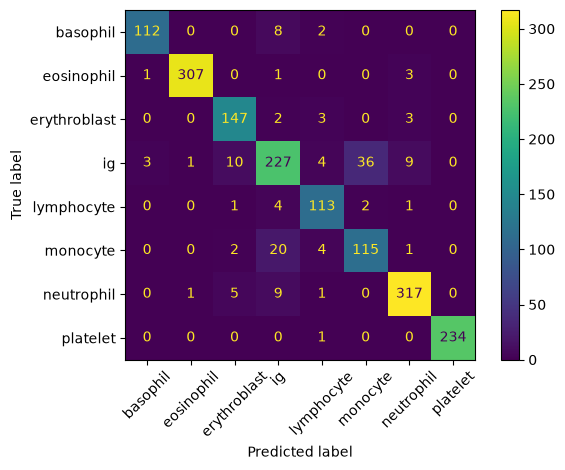

In [15]:
if history['train_loss'] and SHOW_PLOTS:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history['train_loss'], label='train')
    axes[0].plot(history['val_loss'], label='validation')
    axes[0].set(title='Loss', xlabel='epoch')
    axes[0].legend()
    axes[1].plot(history['train_acc'], label='train')
    axes[1].plot(history['val_acc'], label='validation')
    axes[1].set(title='Accuracy', xlabel='epoch')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

if classification_ready and RUN_EXPENSIVE:
    test_loss, test_acc, y_true, y_pred = evaluate_classifier(model, test_loader, criterion, DEVICE)
    print('Test accuracy:', test_acc)
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=CLASS_NAMES, xticks_rotation=45,
    )
    plt.tight_layout()
    plt.show()
else:
    print('Baseline evaluation skipped. Train the baseline before evaluating it.')

# Part III - Data augmentation and transfer learning

Augmentation changes the training images but not their labels. For biological images, every transformation must preserve the biological meaning of the target. A horizontal flip is appropriate only when left--right orientation has no meaning for the cell label; a small rotation is appropriate when the acquisition process does not impose a preferred orientation. Color jitter, cropping, scaling or stronger rotations require the same kind of biological justification.

The next code cell first visualizes these transformations on real images. It then compares the same CNN trained with no augmentation and with the selected horizontal-flip/rotation augmentation. Because the preview and the comparison are guarded by the data and run flags, the notebook can still be read and syntax-checked without downloading or training. Finally, we use an ImageNet-pretrained VGG16, freeze its convolutional backbone and train a new classification head for the blood-cell classes.

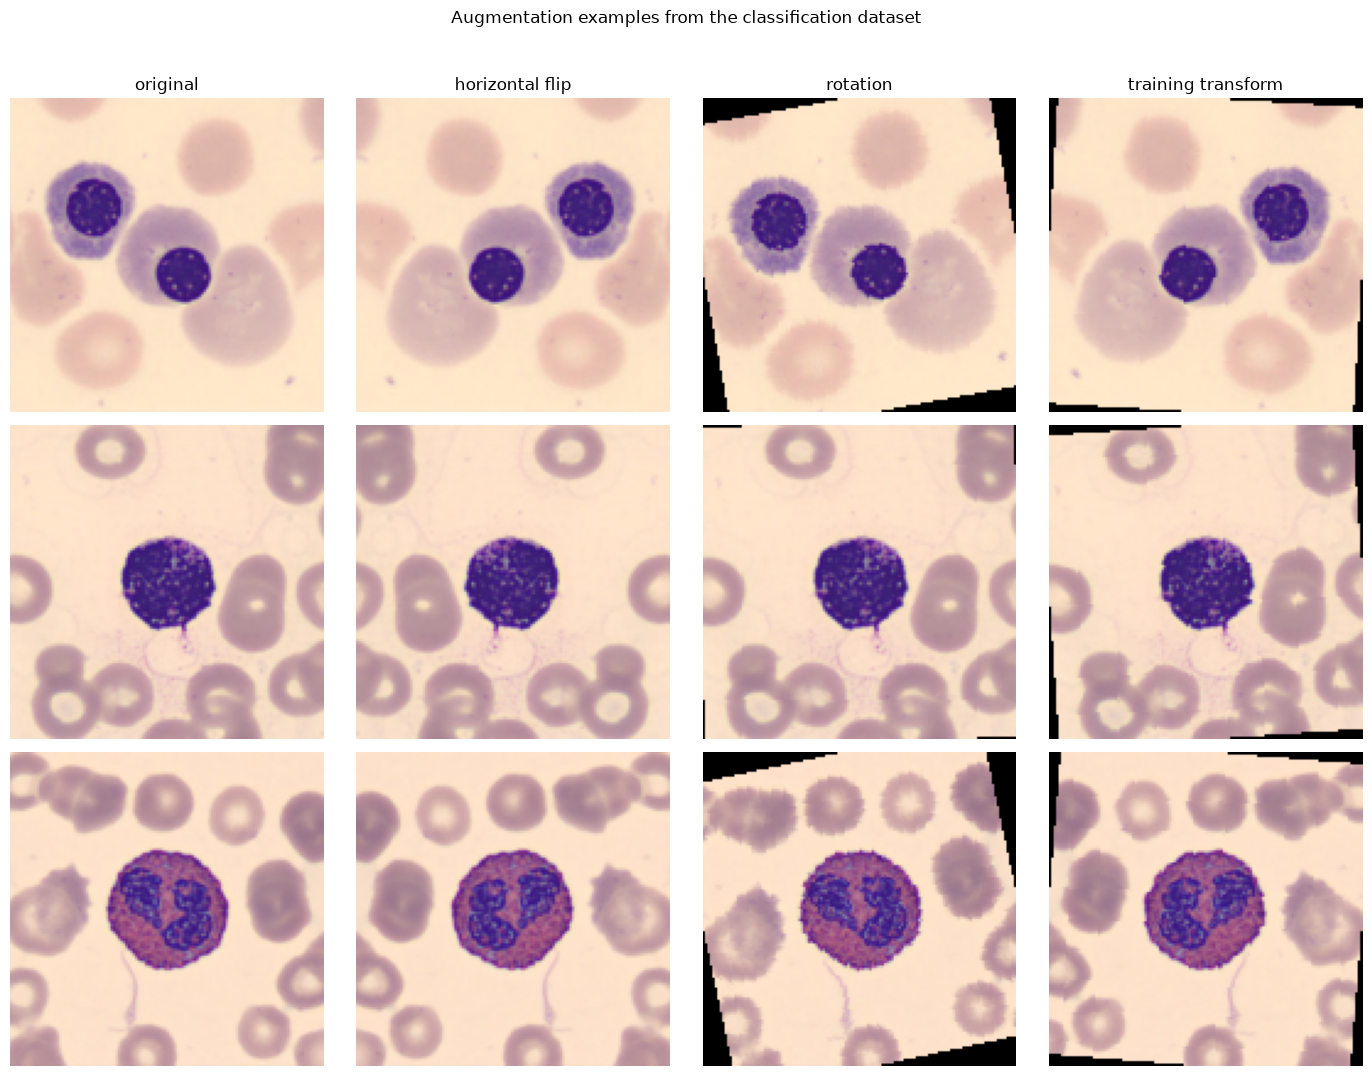

,setting,best_val_accuracy
0,without augmentation,0.873025
1,with augmentation,0.849035


In [16]:
plain_train_transform = eval_transform
augmented_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
])

flip_only_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=1.0),
    transforms.ToTensor(),
])
rotate_only_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
])


def tensor_for_display(tensor):
    return tensor.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()

if classification_ready and SHOW_PLOTS:
    preview_indices = train_indices[:min(3, len(train_indices))]
    preview_transforms = {
        'original': plain_train_transform,
        'horizontal flip': flip_only_transform,
        'rotation': rotate_only_transform,
        'training transform': augmented_train_transform,
    }
    figure, axes = plt.subplots(
        len(preview_indices), len(preview_transforms),
        figsize=(14, 3.5 * max(1, len(preview_indices))), squeeze=False,
    )
    for row, index in enumerate(preview_indices):
        image_path, label = image_dataset.samples[int(index)]
        with Image.open(image_path) as source_image:
            source_image = source_image.convert('RGB')
            for column, (name, transform) in enumerate(preview_transforms.items()):
                axes[row, column].imshow(tensor_for_display(transform(source_image)))
                axes[row, column].axis('off')
                if row == 0:
                    axes[row, column].set_title(name)
        axes[row, 0].set_ylabel(CLASS_NAMES[int(label)], rotation=90, fontsize=10)
    figure.suptitle('Augmentation examples from the classification dataset', y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print('Augmentation visualization skipped because classification data are unavailable or SHOW_PLOTS=False.')

augmentation_results = pd.DataFrame()
def make_train_loader(transform):
    source = datasets.ImageFolder(classification_root, transform=transform)
    return DataLoader(Subset(source, train_indices), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

if classification_ready and RUN_EXPENSIVE:
    result_rows = []
    for name, transform in [
        ('without augmentation', plain_train_transform),
        ('with augmentation', augmented_train_transform),
    ]:
        comparison_model = SimpleCNN(3, len(CLASS_NAMES), IMAGE_SIZE).to(DEVICE)
        comparison_loader = make_train_loader(transform)
        comparison_criterion = nn.CrossEntropyLoss()
        comparison_optimizer = torch.optim.Adam(comparison_model.parameters(), lr=1e-3)
        best_val_accuracy = 0.0
        for _ in range(3):
            train_one_epoch(comparison_model, comparison_loader, comparison_criterion, comparison_optimizer, DEVICE)
            _, val_accuracy, _, _ = evaluate_classifier(
                comparison_model, val_loader, comparison_criterion, DEVICE,
            )
            best_val_accuracy = max(best_val_accuracy, val_accuracy)
        result_rows.append({'setting': name, 'best_val_accuracy': best_val_accuracy})
    augmentation_results = pd.DataFrame(result_rows)
    display(augmentation_results)
else:
    print('Augmentation comparison skipped. Set RUN_EXPENSIVE=True to train both settings.')

# Part IV - CVAT and object detection

Classification answers **what is present in an image**. Detection answers **what is present and where it is**, using one bounding box per object.

### CVAT recommendation

On Windows, use Docker Desktop with WSL2 rather than trying to install the complete CVAT stack natively. This keeps the annotation service isolated and still lets you work from Chrome. For a shared course installation, deploy the same Docker Compose stack on Linux. The annotation workflow is:

1. Create a task and upload a small representative image subset.
2. Define the biological labels and write an annotation protocol.
3. Annotate a pilot subset and review ambiguous objects.
4. Export YOLO format and validate the exported files before training.

Important protocol decisions include border colonies, touching colonies, very small objects, artifacts and whether overlapping objects receive separate boxes.

In [17]:
DETECTION_ROOT = WEEK7_ROOT / 'detection' / 'colonies_annotation'
DETECTION_IMAGE_ROOT = DETECTION_ROOT / 'obj_train_data'
image_extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}
detection_images = sorted(path for path in DETECTION_IMAGE_ROOT.iterdir() if path.suffix.lower() in image_extensions) if DETECTION_IMAGE_ROOT.exists() else []
detection_labels = [path.with_suffix('.txt') for path in detection_images]
detection_table = pd.DataFrame({
    'image': [path.name for path in detection_images],
    'label_exists': [path.exists() for path in detection_labels],
})
display(detection_table.head())
print('Images:', len(detection_images))
print('Missing labels:', int((~detection_table['label_exists']).sum()) if len(detection_table) else 'n/a')
print('Class names:', (DETECTION_ROOT / 'obj.names').read_text().splitlines() if (DETECTION_ROOT / 'obj.names').exists() else 'missing')

,image,label_exists
0,10 open.jpg,True
1,11 open.jpg,True
2,12 open.jpg,True
3,13 open.jpg,True
4,14 open.jpg,True


Images: 92
Missing labels: 0
Class names: ['colony']


## YOLO label format and visual annotation check

Each non-empty annotation line has five values:

```text
class_id  x_center  y_center  width  height
```

The four box coordinates are normalized to `[0, 1]` relative to image width and height. In this dataset `obj.names` contains one class: `colony`. The next cell overlays several ground-truth boxes on the raw images. This visual check is essential: a parser can accept syntactically valid numbers while still using the wrong image, coordinate convention or class mapping.

In [18]:
def read_yolo_label(label_path):
    records = []
    if not label_path.exists():
        return records
    for line_number, line in enumerate(label_path.read_text(encoding='utf-8').splitlines(), start=1):
        if not line.strip():
            continue
        values = line.split()
        if len(values) != 5:
            raise ValueError(f'{label_path}:{line_number} should have five values')
        class_id = int(values[0])
        coordinates = np.asarray([float(value) for value in values[1:]], dtype=float)
        if not np.all((coordinates >= 0) & (coordinates <= 1)):
            raise ValueError(f'Coordinates outside [0, 1] in {label_path}:{line_number}')
        records.append((class_id, *coordinates))
    return records

annotation_summary = []
for image_path in detection_images:
    labels = read_yolo_label(image_path.with_suffix('.txt'))
    annotation_summary.append({
        'image': image_path.name,
        'objects': len(labels),
        'classes': sorted(set(row[0] for row in labels)),
    })
display(pd.DataFrame(annotation_summary).head())
print('Parsed annotation files:', len(annotation_summary))

,image,objects,classes
0,10 open.jpg,72,[0]
1,11 open.jpg,112,[0]
2,12 open.jpg,78,[0]
3,13 open.jpg,18,[0]
4,14 open.jpg,38,[0]


Parsed annotation files: 92


## Visualize the ground-truth boxes

The YOLO file stores normalized center coordinates and box dimensions. Here we convert them back to pixel coordinates and draw the actual rectangles on the image. This is the first check that the image--label pairing and coordinate convention are correct.

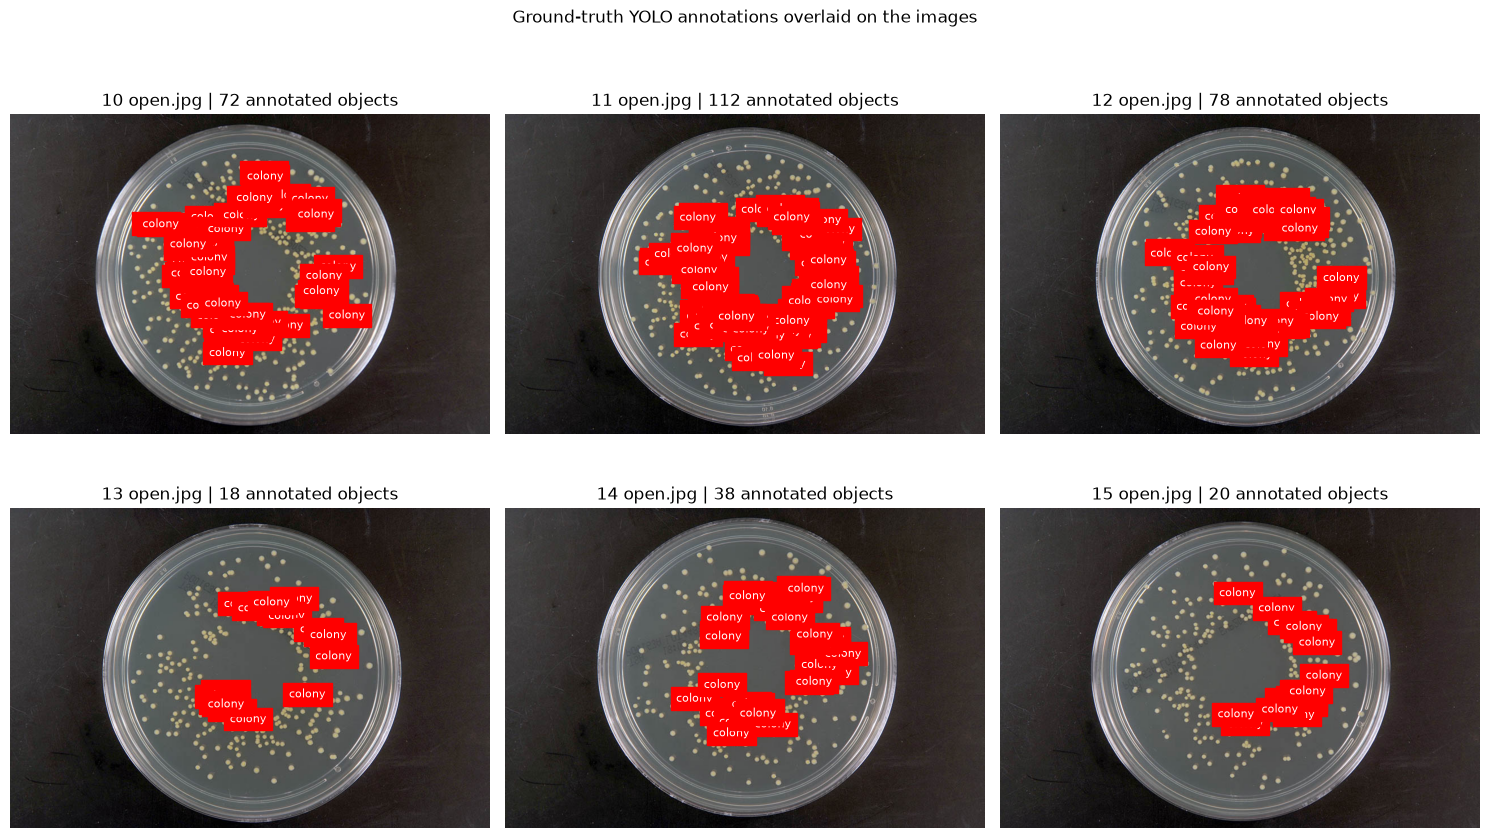

In [19]:
DETECTION_CLASS_NAMES = ['colony']
names_path = DETECTION_ROOT / 'obj.names'
if names_path.exists():
    DETECTION_CLASS_NAMES = names_path.read_text(encoding='utf-8').splitlines()


def draw_ground_truth_boxes(axis, image_path):
    """Draw normalized YOLO labels after converting them to pixel coordinates."""
    image = np.asarray(Image.open(image_path).convert('RGB'))
    height, width = image.shape[:2]
    axis.imshow(image)
    labels = read_yolo_label(image_path.with_suffix('.txt'))
    for class_id, x_center, y_center, box_width, box_height in labels:
        x0 = (x_center - box_width / 2) * width
        y0 = (y_center - box_height / 2) * height
        rectangle = plt.Rectangle(
            (x0, y0), box_width * width, box_height * height,
            fill=False, color='red', linewidth=1.5,
        )
        axis.add_patch(rectangle)
        class_name = DETECTION_CLASS_NAMES[class_id] if class_id < len(DETECTION_CLASS_NAMES) else str(class_id)
        axis.text(
            x0, max(0, y0 - 3), class_name,
            color='white', fontsize=8, backgroundcolor='red',
        )
    axis.set_title(f'{image_path.name} | {len(labels)} annotated objects')
    axis.axis('off')


annotated_images = [
    path for path in detection_images
    if read_yolo_label(path.with_suffix('.txt'))
]
if annotated_images and SHOW_PLOTS:
    n_to_show = min(6, len(annotated_images))
    figure, axes = plt.subplots(2, 3, figsize=(15, 9), squeeze=False)
    for axis in axes.ravel():
        axis.axis('off')
    for axis, image_path in zip(axes.ravel(), annotated_images[:n_to_show]):
        draw_ground_truth_boxes(axis, image_path)
    figure.suptitle('Ground-truth YOLO annotations overlaid on the images', y=0.995)
    plt.tight_layout()
    plt.show()
else:
    print('Annotated-image preview skipped because no labelled images were found or SHOW_PLOTS=False.')

In [20]:
import re
import shutil

def resolve_darknet_image(entry):
    relative = Path(entry.strip().replace('\\', '/'))
    candidates = [DETECTION_ROOT / relative]
    if relative.parts and relative.parts[0].lower() == 'data':
        candidates.append(DETECTION_ROOT / Path(*relative.parts[1:]))
    candidates.append(DETECTION_ROOT / 'obj_train_data' / relative.name)
    return next((candidate for candidate in candidates if candidate.exists()), None)

resolved_pairs = []
train_list = DETECTION_ROOT / 'train.txt'
if train_list.exists():
    for line in train_list.read_text(encoding='utf-8', errors='replace').splitlines():
        image_path = resolve_darknet_image(line)
        label_path = image_path.with_suffix('.txt') if image_path is not None else None
        if image_path is not None and image_path.suffix.lower() in image_extensions and label_path.exists():
            resolved_pairs.append((image_path, label_path))

# Remove duplicate paths before splitting. Keep the split deterministic.
resolved_pairs = list(dict((str(image), (image, label)) for image, label in resolved_pairs).values())
rng = np.random.default_rng(RANDOM_STATE)
rng.shuffle(resolved_pairs)
cut = max(1, int(0.8 * len(resolved_pairs))) if resolved_pairs else 0
split_pairs = {'train': resolved_pairs[:cut], 'val': resolved_pairs[cut:]}
YOLO_READY_ROOT = DETECTION_ROOT / 'ultralytics_ready'
yolo_yaml = None
if resolved_pairs:
    for split, pairs in split_pairs.items():
        (YOLO_READY_ROOT / 'images' / split).mkdir(parents=True, exist_ok=True)
        (YOLO_READY_ROOT / 'labels' / split).mkdir(parents=True, exist_ok=True)
        for index, (image_path, label_path) in enumerate(pairs):
            clean_stem = re.sub(r'[^A-Za-z0-9_.-]+', '_', image_path.stem)
            output_name = f'{index:05d}_{clean_stem}{image_path.suffix.lower()}'
            shutil.copy2(image_path, YOLO_READY_ROOT / 'images' / split / output_name)
            shutil.copy2(label_path, YOLO_READY_ROOT / 'labels' / split / f'{Path(output_name).stem}.txt')
    yolo_yaml = YOLO_READY_ROOT / 'colonies.yaml'
    yolo_yaml.write_text(
        f'path: {YOLO_READY_ROOT.resolve().as_posix()}\n'
        'train: images/train\n'
        'val: images/val\n'
        'names:\n  0: colony\n',
        encoding='utf-8',
    )
    missing_labels = [
        image for image in (YOLO_READY_ROOT / 'images').rglob('*')
        if image.suffix.lower() in image_extensions and not (YOLO_READY_ROOT / 'labels' / image.parent.name / f'{image.stem}.txt').exists()
    ]
    assert not missing_labels, f'Missing copied labels: {missing_labels[:3]}'
    print('Resolved image-label pairs:', len(resolved_pairs))
    print('Train/validation pairs:', len(split_pairs['train']), len(split_pairs['val']))
    print('Ultralytics data config:', yolo_yaml)
else:
    print('No complete image/label pairs found. Check train.txt, obj_train_data and label suffixes.')

Resolved image-label pairs: 92
Train/validation pairs: 73 19
Ultralytics data config: C:\Users\user\Desktop\kse\practicals\week7\detection\colonies_annotation\ultralytics_ready\colonies.yaml


## YOLO workflow: train, evaluate and select images for annotation

The detection workflow is deliberately separated into small steps. We first prepare the labelled training data, choose one model to train, evaluate its saved `best.pt` on the validation split, and only then run inference on the separate `detection/test` images. The test images have no labels here, so uncertainty is estimated from prediction confidence and disagreement under a horizontal flip; the highest-ranked images become candidates for additional CVAT annotation.

## YOLO configuration

In [21]:
from ultralytics import YOLO

YOLO_CHECKPOINTS = {
    'YOLOv8n': 'yolov8n.pt',
    'YOLOv8s': 'yolov8s.pt',
    'YOLO11n': 'yolo11n.pt',
    'YOLO11s': 'yolo11s.pt',
    'YOLO26n': 'yolo26n.pt',
    'YOLO26s': 'yolo26s.pt',
}
SELECTED_YOLO_NAME = 'YOLO11s'
SELECTED_YOLO_CHECKPOINT = YOLO_CHECKPOINTS[SELECTED_YOLO_NAME]
RUN_YOLO_TRAINING = RUN_EXPENSIVE
RUN_YOLO_COMPARISON = False
YOLO_PROJECT = DETECTION_ROOT / 'runs'
YOLO_RUN_NAME = 'course_' + SELECTED_YOLO_NAME


def cuda_nms_available():
    if not torch.cuda.is_available():
        return False
    try:
        boxes = torch.tensor([[0.0, 0.0, 10.0, 10.0]], device='cuda')
        scores = torch.tensor([1.0], device='cuda')
        torchvision.ops.nms(boxes, scores, 0.5)
        return True
    except Exception as error:
        print('CUDA torchvision NMS is unavailable:', repr(error))
        return False


YOLO_DEVICE = 0 if cuda_nms_available() else 'cpu'
YOLO_AMP = YOLO_DEVICE != 'cpu'
print('Selected checkpoint:', SELECTED_YOLO_CHECKPOINT)
print('YOLO device:', YOLO_DEVICE)

Selected checkpoint: yolo11s.pt
YOLO device: 0


## Train one selected YOLO model

The default selected model is YOLO11-nano. Set `RUN_EXPENSIVE=True` to train it; otherwise the workflow falls back to the existing `week7/best.pt` checkpoint.

In [22]:
trained_best_path = WEEK7_ROOT / 'best.pt'

if RUN_YOLO_TRAINING and yolo_yaml is not None:
    selected_detector = YOLO(SELECTED_YOLO_CHECKPOINT)
    selected_detector.train(
        data=str(yolo_yaml),
        epochs=10,
        imgsz=640,
        batch=8,
        seed=RANDOM_STATE,
        device=YOLO_DEVICE,
        amp=YOLO_AMP,
        project=str(YOLO_PROJECT),
        name=YOLO_RUN_NAME,
        exist_ok=True,
    )
    candidate_best_path = YOLO_PROJECT / YOLO_RUN_NAME / 'weights' / 'best.pt'
    if candidate_best_path.exists():
        trained_best_path = candidate_best_path
    print('Trained checkpoint:', trained_best_path)
else:
    print('YOLO training skipped. Set RUN_EXPENSIVE=True to train the selected model.')

Ultralytics 8.4.182  Python-3.11.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12287MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\user\Desktop\kse\practicals\week7\detection\colonies_annotation\ultralytics_ready\colonies.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic

## Optional comparison of YOLO model families

This remains separate from the main workflow because training three models is substantially more expensive.

In [23]:
yolo_comparison = pd.DataFrame()
comparison_rows = []
for model_name, checkpoint in YOLO_CHECKPOINTS.items():
        detector = YOLO(checkpoint)
        detector.train(
            data=str(yolo_yaml), epochs=10, imgsz=640, batch=8,
            seed=RANDOM_STATE, device=YOLO_DEVICE, amp=YOLO_AMP,
            project=str(YOLO_PROJECT), name=model_name, exist_ok=True,
        )
        metrics = detector.val(
            data=str(yolo_yaml), split='val', imgsz=640, device=YOLO_DEVICE,
        )
        comparison_rows.append({
            'model': model_name,
            'parameters': sum(parameter.numel() for parameter in detector.model.parameters()),
            'precision': float(metrics.box.mp),
            'recall': float(metrics.box.mr),
            'mAP50': float(metrics.box.map50),
            'mAP50-95': float(metrics.box.map),
        })
yolo_comparison = pd.DataFrame(comparison_rows)
display(yolo_comparison)


Ultralytics 8.4.182  Python-3.11.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12287MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\user\Desktop\kse\practicals\week7\detection\colonies_annotation\ultralytics_ready\colonies.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic

,model,parameters,precision,recall,mAP50,mAP50-95
0,YOLOv8n,3138003,0.026649,0.178086,0.011923,0.003006
1,YOLOv8s,11135987,0.026770,0.192749,0.010918,0.002556
2,YOLO11n,2604883,0.029106,0.196214,0.025428,0.007252
3,YOLO11s,9428179,0.047498,0.298320,0.031269,0.007832
4,YOLO26n,2533886,0.086450,0.081312,0.020074,0.005261
5,YOLO26s,9948638,0.066121,0.272194,0.035916,0.008966


## Evaluate the trained checkpoint on the validation split

`best.pt` is evaluated on the held-out validation images that were created from the labelled training data. These metrics are different from the later uncertainty review: validation has ground-truth boxes, while the test folder is currently unlabeled.

In [24]:
RUN_BEST_MODEL_EVAL = True
best_model = None
best_metrics = None
best_performance = pd.DataFrame()

if RUN_BEST_MODEL_EVAL and trained_best_path.exists() and yolo_yaml is not None:
    best_model = YOLO(str(trained_best_path))
    best_metrics = best_model.val(
        data=str(yolo_yaml), split='val', imgsz=640,
        device=YOLO_DEVICE, verbose=False,
    )
    best_performance = pd.DataFrame([{
        'checkpoint': str(trained_best_path),
        'precision': float(best_metrics.box.mp),
        'recall': float(best_metrics.box.mr),
        'mAP50': float(best_metrics.box.map50),
        'mAP50-95': float(best_metrics.box.map),
    }])
    display(best_performance)
else:
    print('Checkpoint evaluation skipped because best.pt, YAML or the evaluation flag is unavailable.')

Ultralytics 8.4.182  Python-3.11.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12287MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1918.1±1019.0 MB/s, size: 285.1 KB)
val: Scanning C:\Users\user\Desktop\kse\practicals\week7\detection\colonies_annotation\ultralytics_ready\labels\val.cache... 48 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 48/48  0.0s
WARNING Dataset images contain up to 594 objects (val=594), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=594 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.7s/it 8.1s1.9s4s
                   all         48       3751     0.0475      0.298     0.0313    0.00783
Speed: 1.9ms pre

,checkpoint,precision,recall,mAP50,mAP50-95
0,C:\Users\user\Desktop\kse\practicals\week7\det...,0.047498,0.29832,0.031269,0.007832


## IoU helpers for test-time disagreement

The test images do not have ground-truth boxes, so a true annotation-based IoU cannot yet be calculated. Instead, the model predicts on the original image and a horizontally flipped copy. After mapping the flipped boxes back, low class-aware IoU indicates localization instability.

In [25]:
def boxes_from_result(result):
    if result.boxes is None or len(result.boxes) == 0:
        return np.empty((0, 4)), np.empty(0, dtype=int), np.empty(0)
    return (
        result.boxes.xyxy.detach().cpu().numpy(),
        result.boxes.cls.detach().cpu().numpy().astype(int),
        result.boxes.conf.detach().cpu().numpy(),
    )


def box_iou(box_a, box_b):
    left, top = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    right, bottom = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    intersection = max(0.0, right - left) * max(0.0, bottom - top)
    area_a = max(0.0, box_a[2] - box_a[0]) * max(0.0, box_a[3] - box_a[1])
    area_b = max(0.0, box_b[2] - box_b[0]) * max(0.0, box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def flip_boxes_back(boxes, image_width):
    restored = boxes.copy()
    if len(restored):
        restored[:, 0] = image_width - boxes[:, 2]
        restored[:, 2] = image_width - boxes[:, 0]
    return restored


def matched_tta_iou(boxes_a, classes_a, boxes_b, classes_b):
    if len(boxes_a) == 0 and len(boxes_b) == 0:
        return 1.0
    if len(boxes_a) == 0 or len(boxes_b) == 0:
        return 0.0
    used_b, pair_ious = set(), []
    for index_a, class_a in enumerate(classes_a):
        candidates = [
            index_b for index_b, class_b in enumerate(classes_b)
            if index_b not in used_b and class_b == class_a
        ]
        if candidates:
            index_b = max(candidates, key=lambda j: box_iou(boxes_a[index_a], boxes_b[j]))
            used_b.add(index_b)
            pair_ious.append(box_iou(boxes_a[index_a], boxes_b[index_b]))
        else:
            pair_ious.append(0.0)
    pair_ious.extend([0.0] * (len(boxes_b) - len(used_b)))
    return float(np.mean(pair_ious)) if pair_ious else 0.0


def draw_model_boxes(axis, image, boxes, classes, confidences, names):
    axis.imshow(image)
    for box, class_id, confidence in zip(boxes, classes, confidences):
        x0, y0, x1, y1 = box
        axis.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color='lime', linewidth=1.5))
        class_name = names.get(int(class_id), str(class_id)) if isinstance(names, dict) else str(class_id)
        axis.text(x0, max(0, y0 - 3), f'{class_name} {confidence:.2f}', color='black', fontsize=8, backgroundcolor='lime')
    axis.axis('off')

## Inspect predictions on three validation images

Before ranking unlabeled images by uncertainty, inspect ordinary validation predictions. Each row shows the ground-truth boxes beside the boxes predicted by the trained checkpoint. The selection is reproducible because it uses `RANDOM_STATE`.

Validation images selected for prediction inspection:
608.jpg
722.jpg
Ps a 2 total count Raw.png


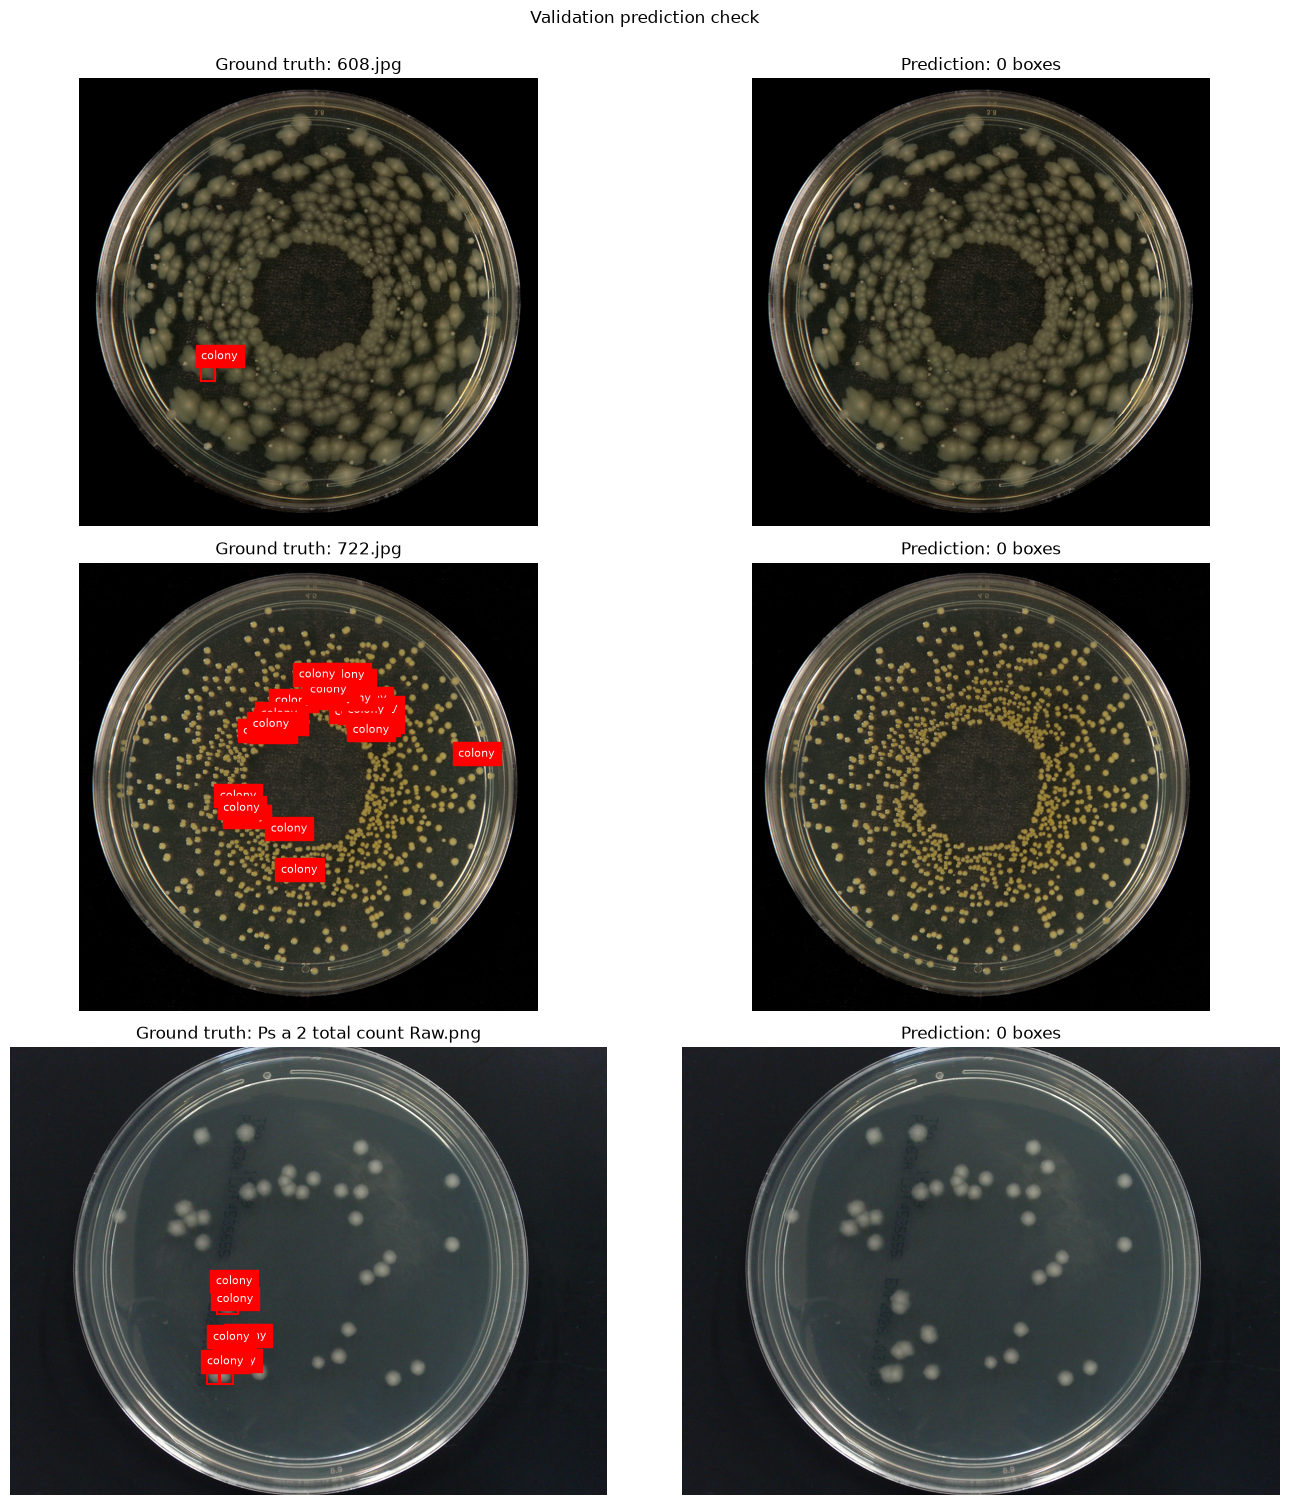

In [26]:
validation_pairs = split_pairs.get('val', []) if 'split_pairs' in globals() else []
if best_model is not None and validation_pairs:
    validation_rng = np.random.default_rng(RANDOM_STATE)
    selected_indices = validation_rng.choice(
        len(validation_pairs), size=min(3, len(validation_pairs)), replace=False,
    )
    selected_validation_pairs = [validation_pairs[int(index)] for index in selected_indices]
    print('Validation images selected for prediction inspection:')
    for image_path, _ in selected_validation_pairs:
        print(image_path.name)

    if SHOW_PLOTS:
        figure, axes = plt.subplots(
            len(selected_validation_pairs), 2,
            figsize=(14, 5 * len(selected_validation_pairs)),
            squeeze=False,
        )
        for row, (image_path, _) in enumerate(selected_validation_pairs):
            image = np.asarray(Image.open(image_path).convert('RGB'))
            result = best_model.predict(
                image, imgsz=640, conf=0.25, device=YOLO_DEVICE, verbose=False,
            )[0]
            boxes, classes, confidences = boxes_from_result(result)
            draw_ground_truth_boxes(axes[row, 0], image_path)
            axes[row, 0].set_title(f'Ground truth: {image_path.name}')
            draw_model_boxes(axes[row, 1], image, boxes, classes, confidences, best_model.names)
            axes[row, 1].set_title(f'Prediction: {len(boxes)} boxes')
        figure.suptitle('Validation prediction check', y=1.0)
        plt.tight_layout()
        plt.show()
else:
    print('Validation prediction preview skipped because the trained model or validation pairs are unavailable.')

## Run the trained model on `detection/test`

These images are intentionally kept separate from the labelled training and validation images. We do not treat the uncertainty score as a ground-truth error. Instead, we use it to prioritize images for additional CVAT annotation, after which true precision, recall and IoU can be calculated.

Unlabeled test images: 28
Highest-priority images for additional CVAT annotation:


,image,path,predictions,mean_confidence,flip_iou,count_difference,uncertainty
0,41 open.jpg,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5
1,712.jpg,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5
2,E c 2 RAW.png,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5
3,frame_106.png,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5
4,frame_107.png,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5
5,frame_122.png,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5
6,frame_321.png,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5
7,frame_338.png,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5
8,frame_61.png,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5
9,frame_62.png,C:\Users\user\Desktop\kse\practicals\week7\det...,0,0.0,1.0,0.0,0.5


Filenames:
41 open.jpg
712.jpg
E c 2 RAW.png
frame_106.png
frame_107.png
frame_122.png
frame_321.png
frame_338.png
frame_61.png
frame_62.png


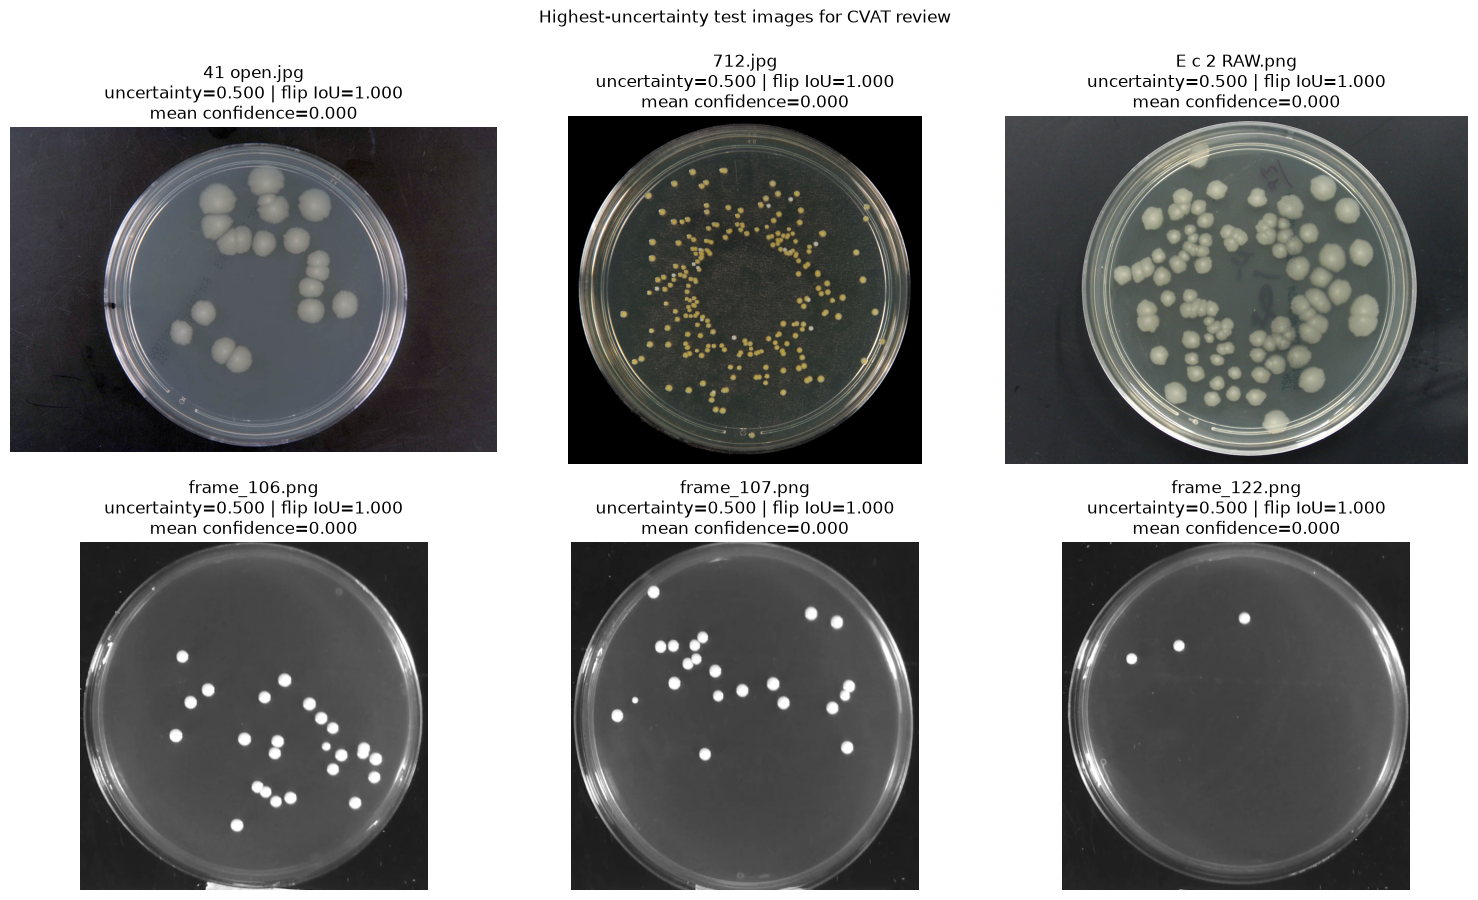

In [27]:
DETECTION_TEST_ROOT = WEEK7_ROOT / 'detection' / 'test'
test_images = sorted(
    path for path in DETECTION_TEST_ROOT.iterdir()
    if path.suffix.lower() in image_extensions
) if DETECTION_TEST_ROOT.exists() else []
print('Unlabeled test images:', len(test_images))

uncertainty_rows = []
prediction_cache = {}
if best_model is not None and test_images:
    for image_path in test_images:
        image = np.asarray(Image.open(image_path).convert('RGB'))
        flipped_image = np.ascontiguousarray(image[:, ::-1, :])
        original_result = best_model.predict(image, imgsz=640, conf=0.25, device=YOLO_DEVICE, verbose=False)[0]
        flipped_result = best_model.predict(flipped_image, imgsz=640, conf=0.25, device=YOLO_DEVICE, verbose=False)[0]
        boxes_a, classes_a, confidences_a = boxes_from_result(original_result)
        boxes_b, classes_b, _ = boxes_from_result(flipped_result)
        boxes_b = flip_boxes_back(boxes_b, image.shape[1])
        flip_iou = matched_tta_iou(boxes_a, classes_a, boxes_b, classes_b)
        mean_confidence = float(np.mean(confidences_a)) if len(confidences_a) else 0.0
        count_difference = abs(len(boxes_a) - len(boxes_b)) / max(1, max(len(boxes_a), len(boxes_b)))
        uncertainty = (
            0.5 * (1.0 - mean_confidence)
            + 0.4 * (1.0 - flip_iou)
            + 0.1 * count_difference
        )
        uncertainty_rows.append({
            'image': image_path.name,
            'path': str(image_path),
            'predictions': len(boxes_a),
            'mean_confidence': mean_confidence,
            'flip_iou': flip_iou,
            'count_difference': count_difference,
            'uncertainty': uncertainty,
        })
        prediction_cache[str(image_path)] = (image, boxes_a, classes_a, confidences_a)

    uncertainty_table = pd.DataFrame(uncertainty_rows).sort_values('uncertainty', ascending=False).reset_index(drop=True)
    print('Highest-priority images for additional CVAT annotation:')
    display(uncertainty_table.head(10))
    print('Filenames:')
    for image_name in uncertainty_table.head(10)['image']:
        print(image_name)

    if SHOW_PLOTS and len(uncertainty_table):
        top_rows = uncertainty_table.head(6)
        figure, axes = plt.subplots(2, 3, figsize=(15, 9), squeeze=False)
        for axis in axes.ravel():
            axis.axis('off')
        for axis, row in zip(axes.ravel(), top_rows.itertuples(index=False)):
            image, boxes, classes, confidences = prediction_cache[row.path]
            draw_model_boxes(axis, image, boxes, classes, confidences, best_model.names)
            axis.set_title(
                f'{row.image}\nuncertainty={row.uncertainty:.3f} | flip IoU={row.flip_iou:.3f}\n'
                f'mean confidence={row.mean_confidence:.3f}'
            )
        figure.suptitle('Highest-uncertainty test images for CVAT review', y=0.995)
        plt.tight_layout()
        plt.show()
else:
    print('Test review skipped because the trained model or test images are unavailable.')

# Part IV - Cellpose instance segmentation

The segmentation folder contains two microscopy sources:

- `brightfield`: regular transmitted-light microscopy;
- `clsm`: confocal laser scanning microscopy images.

Cellpose predicts a pixel-level instance label for each object. The same model may behave differently across modalities, so inspect representative images and document the channel interpretation, diameter setting and failure cases.

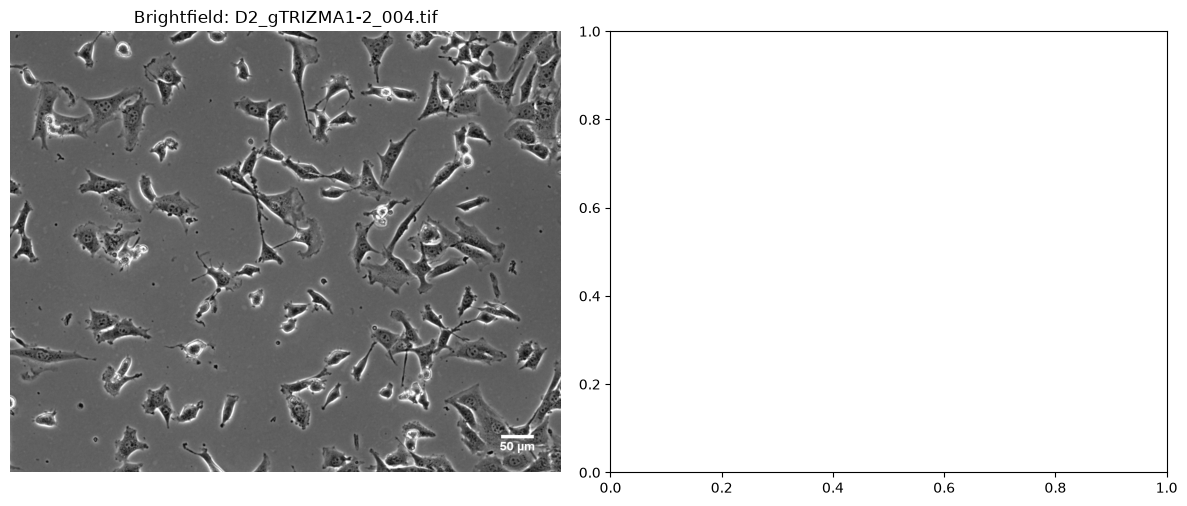

In [34]:
SEGMENTATION_ROOT = next((WEEK7_ROOT / name for name in ('segemntation', 'segmentation') if (WEEK7_ROOT / name).is_dir()), WEEK7_ROOT / 'segmentation')
brightfield_files = sorted((SEGMENTATION_ROOT / 'brightfield').glob('*')) if (SEGMENTATION_ROOT / 'brightfield').exists() else []

if SHOW_PLOTS and brightfield_files:
    figure, axes = plt.subplots(1, 2, figsize=(12, 5))
    for axis, path, title in zip(axes, [brightfield_files[4]], ['Brightfield']):
        axis.imshow(Image.open(path), cmap='gray')
        axis.set_title(f'{title}: {path.name}')
        axis.axis('off')
    plt.tight_layout()
    plt.show()

## Cellpose model and inference parameters

For a grayscale image, `channels=[0, 0]` indicates that the same image is used without a separate nuclear channel. For a multichannel experiment, the channel specification must be changed and recorded. The cell diameter is a biological and imaging assumption, not just a software setting.

The main parameters below control different parts of the segmentation decision:

| Parameter | Meaning | Typical effect |
|---|---|---|
| `model` | Name or path of the pretrained Cellpose model checkpoint. | A model trained for a different modality or object type can change which structures are recognised. |
| `flow_threshold` | Maximum allowed flow error for keeping a predicted mask. | Lower values are more strict; higher values keep more irregular or uncertain masks. |
| `cellprob_threshold` | Pixel-level cell-probability threshold used to form masks. | Lower values usually find more or larger objects; higher values are more conservative. |
| `min_size` | Minimum object area in pixels. | Increasing it removes small fragments and noise; decreasing it preserves small objects. |

The values are not universal biological truths. They should be selected using representative images and checked against the microscopy modality, expected cell size and annotation quality.

In [ ]:
# Choose one configuration for the inference cell below.
# These settings are deliberately explicit so that parameter changes can be compared.
CELLPOSE_PARAMETER_SETS = {
    'default': {
        'model': 'cpsam',
        'flow_threshold': 0.4,
        'cellprob_threshold': 0.0,
        'min_size': 15,
    },
    'sensitive': {
        'model': 'cpsam',
        'flow_threshold': 0.2,
        'cellprob_threshold': -1.0,
        'min_size': 5,
    },
    'conservative': {
        'model': 'cpsam',
        'flow_threshold': 0.8,
        'cellprob_threshold': 0.5,
        'min_size': 30,
    },
}

CELLPOSE_SETTING = 'default'
CELLPOSE_PARAMS = CELLPOSE_PARAMETER_SETS[CELLPOSE_SETTING]
display(pd.DataFrame(CELLPOSE_PARAMETER_SETS).T)
print(f'Selected Cellpose setting: {CELLPOSE_SETTING}')

In [ ]:
cellpose_masks = None
cellpose_image = None
cellpose_source = (
    brightfield_files[4] if len(brightfield_files) > 4
    else (brightfield_files[0] if brightfield_files else None)
)

if RUN_EXPENSIVE and cellpose_source is not None:
    from cellpose import models as cellpose_models
    cellpose_model = cellpose_models.CellposeModel(
        gpu=torch.cuda.is_available(),
        pretrained_model=CELLPOSE_PARAMS['model'])
    cellpose_image = np.asarray(Image.open(cellpose_source).convert('L'), dtype=np.float32)
    cellpose_result = cellpose_model.eval(
        cellpose_image,
        channels=[0, 0],
        diameter=None,
        flow_threshold=CELLPOSE_PARAMS['flow_threshold'],
        cellprob_threshold=CELLPOSE_PARAMS['cellprob_threshold'],
        min_size=CELLPOSE_PARAMS['min_size'],
    )
    cellpose_masks = cellpose_result[0]
    print('Cellpose source:', cellpose_source.name)
    print('Used Cellpose settings:', CELLPOSE_PARAMS)
else:
    print('Cellpose inference skipped. Set RUN_EXPENSIVE=True to run it.')

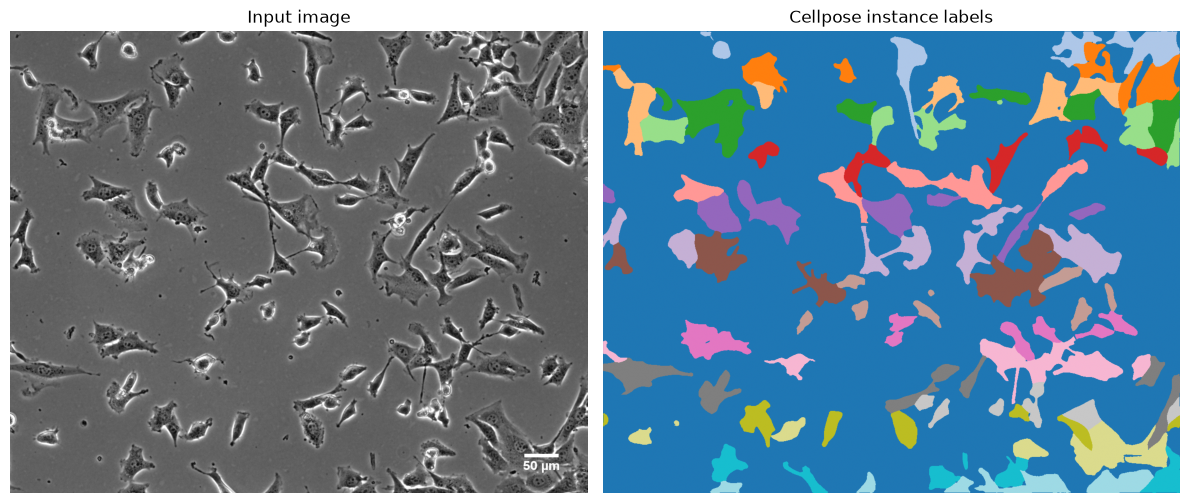

In [36]:
if cellpose_masks is not None and SHOW_PLOTS:
    figure, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(cellpose_image, cmap='gray')
    axes[0].set_title('Input image')
    axes[1].imshow(cellpose_masks, cmap='tab20')
    axes[1].set_title('Cellpose instance labels')
    for axis in axes:
        axis.axis('off')
    plt.tight_layout()
    plt.show()

### From masks to measurements

A segmentation mask can be converted into a table of objects. Typical features include area, centroid, bounding-box dimensions, eccentricity, solidity, mean intensity and texture summaries. Inspect whether the mask contains one label per cell, merged cells, fragments or background labels before trusting the measurements.

In [31]:
if cellpose_masks is not None:
    from skimage.measure import regionprops_table
    morphology_table = pd.DataFrame(
        regionprops_table(
            cellpose_masks,
            intensity_image=cellpose_image,
            properties=('label', 'area', 'centroid', 'bbox', 'eccentricity', 'solidity', 'mean_intensity'),
        )
    )
    display(morphology_table.head())
else:
    print('Run Cellpose before extracting morphology.')

,label,area,centroid-0,centroid-1,bbox-0,bbox-1,bbox-2,bbox-3,eccentricity,solidity,mean_intensity
0,1,108.0,3.064815,353.268519,0,345,8,363,0.886062,0.939130,0.231481
1,2,247.0,6.352227,395.696356,0,386,15,407,0.675825,0.961089,0.420594
2,3,228.0,4.991228,417.596491,0,405,13,430,0.891017,0.901186,-0.214460
3,4,186.0,5.623656,482.419355,0,473,13,492,0.769024,0.958763,0.429830
4,5,560.0,33.691071,894.171429,1,887,71,904,0.988028,0.858896,0.717783


# Part V - 3D microscopy and VGG13D embeddings

The `3d` folder contains small cropped microscopy volumes stored as multi-page TIFF files. We first inspect their dimensions and intensity ranges, then view one volume interactively in Napari. Finally, a compact VGG13D-style network converts each volume into a fixed-length embedding. The expensive cells are opt-in because 3D convolutions require substantially more memory than 2D convolutions.

In [ ]:
from PIL import ImageSequence

THREED_ROOT = WEEK7_ROOT / '3d'
three_d_candidates = (
    sorted(path for path in THREED_ROOT.rglob('*') if path.suffix.lower() in {'.tif', '.tiff'})
    if THREED_ROOT.exists() else []
)
# Prefer the original multi-page volumes when both original and exported
# *_volume.tif files are present; otherwise use all available TIFF files.
three_d_paths = [
    path for path in three_d_candidates
    if not path.name.lower().endswith('_volume.tif')
] or three_d_candidates

def read_tiff_volume(path):
    """Read a multi-page TIFF as a float32 array with axes (Z, Y, X)."""
    with Image.open(path) as image:
        frames = [
            np.asarray(frame.convert('F'), dtype=np.float32)
            for frame in ImageSequence.Iterator(image)
        ]
    if not frames:
        raise ValueError(f'No image planes found in {path}')
    return np.stack(frames, axis=0)

three_d_inventory_rows = []
for path in three_d_paths:
    try:
        array = read_tiff_volume(path)
        three_d_inventory_rows.append({
            'file': path.name,
            'roi': path.parent.name,
            'shape_ZYX': array.shape,
            'dtype': str(array.dtype),
            'min': float(np.nanmin(array)),
            'max': float(np.nanmax(array)),
            'mean': float(np.nanmean(array)),
            'p01': float(np.nanpercentile(array, 1)),
            'p99': float(np.nanpercentile(array, 99)),
        })
    except Exception as error:
        three_d_inventory_rows.append({'file': path.name, 'error': repr(error)})

three_d_inventory = pd.DataFrame(three_d_inventory_rows)
display(three_d_inventory)

selected_3d_path = three_d_paths[0] if three_d_paths else None
volume_3d = read_tiff_volume(selected_3d_path) if selected_3d_path is not None else None
if volume_3d is not None:
    print('Selected volume:', selected_3d_path)
    print('Volume axes: (Z, Y, X) =', volume_3d.shape)
else:
    print('No *_volume.tif files found in', THREED_ROOT)

### Inspecting a 3D volume

A volume is represented here as `(Z, Y, X)`: a stack of 2D planes along the microscope depth axis. The intensity range should be checked before visualization because microscopy data may be stored as 8-bit, 16-bit or floating-point values. The preview below is a static check; Napari provides the interactive slice-by-slice view.

In [ ]:
if volume_3d is not None and SHOW_PLOTS:
    z_index = volume_3d.shape[0] // 2
    y_index = volume_3d.shape[1] // 2
    x_index = volume_3d.shape[2] // 2
    low, high = np.nanpercentile(volume_3d, [1, 99])
    figure, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(volume_3d[z_index], cmap='gray', vmin=low, vmax=high)
    axes[0].set_title(f'XY plane, z={z_index}')
    axes[1].imshow(volume_3d[:, y_index, :], cmap='gray', vmin=low, vmax=high, aspect='auto')
    axes[1].set_title(f'XZ plane, y={y_index}')
    axes[2].imshow(volume_3d[:, :, x_index], cmap='gray', vmin=low, vmax=high, aspect='auto')
    axes[2].set_title(f'YZ plane, x={x_index}')
    for axis in axes:
        axis.axis('off')
    figure.suptitle(f'3D volume preview: {selected_3d_path.name}')
    plt.tight_layout()
    plt.show()
else:
    print('3D preview skipped because no volume was found or SHOW_PLOTS=False.')

### Interactive Napari inspection

Napari treats the first axis as depth and lets us scroll through planes, change contrast limits and inspect structures that may be hidden in a single maximum-intensity projection. The viewer is disabled by default because `napari.run()` starts an interactive application.

In [ ]:
RUN_NAPARI_VIEWER = False

if RUN_NAPARI_VIEWER and volume_3d is not None:
    import napari
    napari_viewer = napari.Viewer()
    napari_viewer.add_image(
        volume_3d,
        name=selected_3d_path.stem,
        colormap='gray',
        contrast_limits=tuple(np.nanpercentile(volume_3d, [1, 99])),
    )
    napari.run()
else:
    print('Napari viewer disabled. Set RUN_NAPARI_VIEWER=True to open it.')

### Constructing VGG13D-style embeddings

A 3D convolution slides a small kernel through depth, height and width. The network below follows the VGG idea of two convolutional layers per block, followed by 3D pooling and global average pooling. Global average pooling removes the spatial dimensions, so the final vector has the same length for every input volume.

This notebook defines a compact VGG13D-style model directly in PyTorch because `torchvision` does not provide a pretrained VGG13 3D checkpoint. Unless a checkpoint is supplied, the weights are randomly initialized; the resulting vectors demonstrate the embedding pipeline, but should not be interpreted as biologically meaningful pretrained features.

In [ ]:
class VGG13D(nn.Module):
    def __init__(self, embedding_dim=128):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(1, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv3d(32, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool3d(2),
            nn.Conv3d(32, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv3d(64, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool3d(2),
            nn.Conv3d(64, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv3d(128, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool3d(2),
            nn.Conv3d(128, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv3d(256, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool3d(2),
        )
        self.pool = nn.AdaptiveAvgPool3d((1, 1, 1))
        self.embedding = nn.Linear(256, embedding_dim)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(start_dim=1)
        return self.embedding(x)

vgg13d_demo = VGG13D(embedding_dim=128)
print(vgg13d_demo)

In [ ]:
RUN_3D_EMBEDDINGS = False
VGG13D_INPUT_SIZE = (32, 128, 128)
VGG13D_EMBEDDING_DIM = 128
VGG13D_CHECKPOINT = None  # optionally set a local path to compatible trained weights

def prepare_volume_for_vgg13d(path, output_size=VGG13D_INPUT_SIZE):
    array = read_tiff_volume(path)
    array = np.nan_to_num(array, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    low, high = np.percentile(array, [1, 99])
    if high <= low:
        normalized = np.zeros_like(array, dtype=np.float32)
    else:
        normalized = np.clip((array - low) / (high - low), 0, 1)
    tensor = torch.from_numpy(normalized.copy()).float()[None, None]
    return F.interpolate(
        tensor, size=output_size, mode='trilinear', align_corners=False
    ).float()

vgg13d_embeddings = pd.DataFrame()
if RUN_3D_EMBEDDINGS and RUN_EXPENSIVE and three_d_paths:
    vgg13d_model = VGG13D(embedding_dim=VGG13D_EMBEDDING_DIM).to(
        device=DEVICE, dtype=torch.float32
    ).eval()
    if VGG13D_CHECKPOINT is not None and Path(VGG13D_CHECKPOINT).exists():
        checkpoint = torch.load(VGG13D_CHECKPOINT, map_location=DEVICE)
        state_dict = checkpoint.get('state_dict', checkpoint) if isinstance(checkpoint, dict) else checkpoint
        vgg13d_model.load_state_dict(state_dict)
        print('Loaded VGG13D checkpoint:', VGG13D_CHECKPOINT)
    embedding_rows = []
    with torch.no_grad():
        for path in three_d_paths:
            input_volume = prepare_volume_for_vgg13d(path).to(
                device=DEVICE, dtype=torch.float32
            )
            embedding = vgg13d_model(input_volume).squeeze(0).cpu().numpy()
            embedding_rows.append({'roi': path.parent.name, 'file': path.name, **{f'vgg13d_{i}': value for i, value in enumerate(embedding)}})
    vgg13d_embeddings = pd.DataFrame(embedding_rows)
    display(vgg13d_embeddings)
else:
    print('VGG13D embedding extraction skipped. Set RUN_3D_EMBEDDINGS=True and RUN_EXPENSIVE=True to run it.')

### 3D embedding discussion

The embedding table has one row per volume and one column per learned representation coordinate. Before using these vectors for clustering or prediction, document the preprocessing, verify that volumes have comparable physical spacing, and use a trained or otherwise justified checkpoint. A randomly initialized network is useful for demonstrating tensor shapes and the workflow, but it is not a validated biological representation.

# Final comparison

| Task | Input annotation | Model output | Biological question |
|---|---|---|---|
| Classification | one class for an image | class probabilities | What type of cell or sample is this? |
| Detection | one box per object | boxes, classes and confidence | Where are the objects and how many are present? |
| Instance segmentation | one mask per object | pixel-level object identities | What is the exact shape of each object? |
| 3D embeddings | 3D microscopy volume | fixed-length VGG13D-style vector | How can a volume be represented for downstream analysis? |

### Questions for discussion

1. Why is a random image split unsafe if several images come from the same field of view or experiment?
2. Which errors are more serious for colony detection: false positives, false negatives or poor localization?
3. Why can a Cellpose mask be biologically more informative than a bounding box?
4. Which checks should be repeated after converting or copying image files?
5. Which metadata should be retained when exporting microscopy images for machine learning?